In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from PIL import Image

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

In [3]:
# Dataset path

dataset_path = "../data/raw/NEU-DET"

train_images = dataset_path + "/train/Images"
val_images = dataset_path + "/validation/Images"

# Image size

image_size = 224

# Defect classes

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Dataset paths set successfully!")
print("Training path:", train_images)
print("Validation path:", val_images)
print("Total classes:", len(classes))

Dataset paths set successfully!
Training path: ../data/raw/NEU-DET/train/Images
Validation path: ../data/raw/NEU-DET/validation/Images
Total classes: 6


In [4]:
X_train = []
y_train = []

for class_name in classes:

    class_path = os.path.join(train_images, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        img = Image.open(image_path)
        img = img.convert("RGB")
        img = img.resize((image_size, image_size))

        img_array = np.array(img)

        X_train.append(img_array)
        y_train.append(classes.index(class_name))

print("Training images loaded successfully!")
print("Total training images:", len(X_train))

Training images loaded successfully!
Total training images: 1440


In [5]:
X_val = []
y_val = []

for class_name in classes:

    class_path = os.path.join(val_images, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        img = Image.open(image_path)
        img = img.convert("RGB")
        img = img.resize((image_size, image_size))

        img_array = np.array(img)

        X_val.append(img_array)
        y_val.append(classes.index(class_name))

print("Validation images loaded successfully!")
print("Total validation images:", len(X_val))

Validation images loaded successfully!
Total validation images: 360


In [6]:
X_train = np.array(X_train)
y_train = np.array(y_train)

X_val = np.array(X_val)
y_val = np.array(y_val)

print("Training Images Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Validation Images Shape:", X_val.shape)
print("Validation Labels Shape:", y_val.shape)

Training Images Shape: (1440, 224, 224, 3)
Training Labels Shape: (1440,)
Validation Images Shape: (360, 224, 224, 3)
Validation Labels Shape: (360,)


In [7]:
X_train = preprocess_input(X_train)
X_val = preprocess_input(X_val)

print("ResNet50 preprocessing completed!")

print("Training data minimum:", X_train.min())
print("Training data maximum:", X_train.max())

ResNet50 preprocessing completed!
Training data minimum: -123.68
Training data maximum: 151.061


In [8]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

print("ResNet50 model loaded successfully!")

ResNet50 model loaded successfully!


In [9]:
# Freeze all layers of ResNet50

base_model.trainable = False

print("ResNet50 layers freezed successfully!")

ResNet50 layers freezed successfully!


In [10]:
# Get features from ResNet50

x = base_model.output

# Reduce feature maps

x = GlobalAveragePooling2D()(x)

# Add Dense layer

x = Dense(128, activation='relu')(x)

# Add Dropout layer

x = Dropout(0.5)(x)

# Output layer for 6 classes

predictions = Dense(6, activation='softmax')(x)

# Create final model

model = Model(inputs=base_model.input, outputs=predictions)

print("Transfer Learning model created successfully!")

Transfer Learning model created successfully!


In [11]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8806 - loss: 0.3323 - val_accuracy: 0.9861 - val_loss: 0.0476
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.9937 - loss: 0.0316 - val_accuracy: 0.9861 - val_loss: 0.0377
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.9979 - loss: 0.0149 - val_accuracy: 0.9722 - val_loss: 0.0653
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.9993 - loss: 0.0104 - val_accuracy: 0.9889 - val_loss: 0.0446
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.9993 - loss: 0.0088 - val_accuracy: 0.9889 - val_loss: 0.0391
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.9979 - loss: 0.0083 - val_accuracy: 0.9917 - val_loss: 0.0409
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.9993 - loss: 0.0048 - val_accuracy: 0.9889 - val_loss: 0.0472
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.9993 - loss: 0.0048 - val_accuracy: 0.9917 - val_loss:

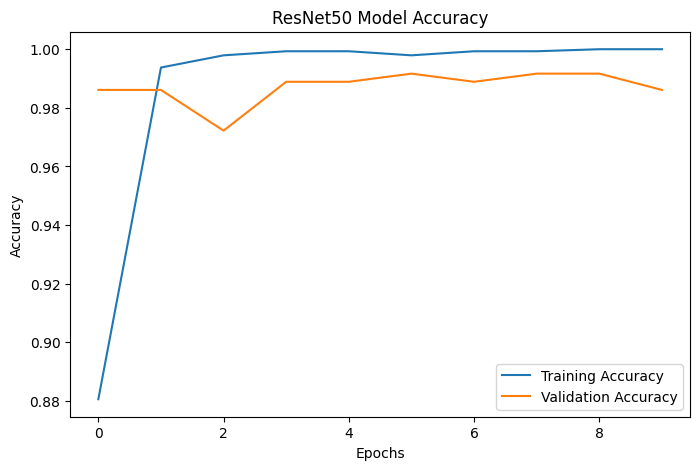

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("ResNet50 Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

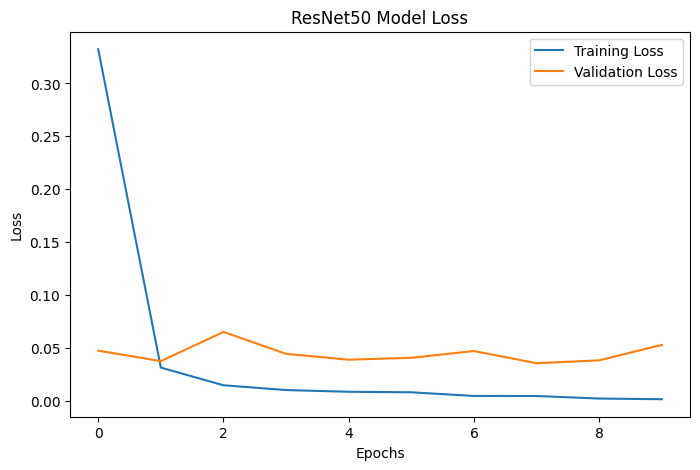

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("ResNet50 Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [15]:
val_loss, val_accuracy = model.evaluate(X_val, y_val)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy * 100, "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 804ms/step - accuracy: 0.9861 - loss: 0.0530
Validation Loss: 0.053046293556690216
Validation Accuracy: 98.61111044883728 %


In [16]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_val)

y_pred = np.argmax(y_pred, axis=1)

print(classification_report(
    y_val,
    y_pred,
    target_names=classes
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 932ms/step
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      0.92      0.96        60
        patches       1.00      1.00      1.00        60
 pitted_surface       0.98      1.00      0.99        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.94      1.00      0.97        60

       accuracy                           0.99       360
      macro avg       0.99      0.99      0.99       360
   weighted avg       0.99      0.99      0.99       360



In [17]:
cm = confusion_matrix(y_val, y_pred)

print("ResNet50 Confusion Matrix:")
print(cm)

ResNet50 Confusion Matrix:
[[60  0  0  0  0  0]
 [ 0 55  0  1  0  4]
 [ 0  0 60  0  0  0]
 [ 0  0  0 60  0  0]
 [ 0  0  0  0 60  0]
 [ 0  0  0  0  0 60]]


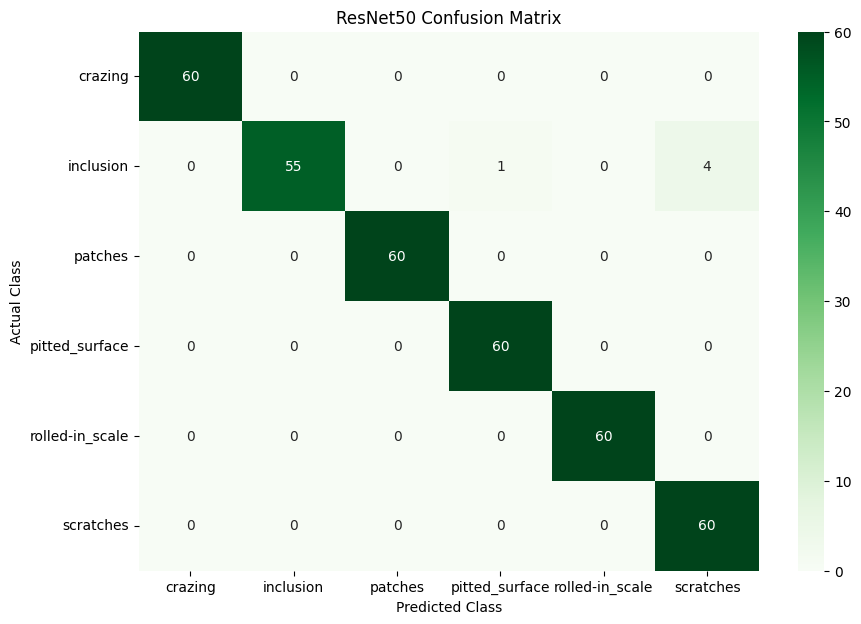

In [18]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=classes,
    yticklabels=classes
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [19]:
model.save("../models/resnet50_transfer_learning.keras")

print("ResNet50 Model saved successfully!")

ResNet50 Model saved successfully!


In [1]:
import os 
print(os.getcwd())

C:\Users\salun\NEU_Surface_Defect_Detection\notebooks
